<a href="https://colab.research.google.com/github/aiagentryk/road-collision-detection/blob/main/road-collision-detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install -q -U ultralytics opencv-python-headless pyyaml matplotlib pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 6.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 88.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 119.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is

In [4]:
import torch
from ultralytics import YOLO

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [5]:
detector = YOLO("yolo26n.pt")
depth_model = YOLO("yolo26n-depth.pt")

print("Object detector and depth model loaded.")

Object detector and depth model loaded.


In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("abdelrahmanelgharibx/mono-kitti")

print("Path to dataset files:", path)

100%|██████████| 5.69G/5.69G [01:18<00:00, 77.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/abdelrahmanelgharibx/mono-kitti/versions/1


In [20]:
from pathlib import Path

ROOT = Path(
    "/root/.cache/kagglehub/datasets/"
    "abdelrahmanelgharibx/mono-kitti/versions/1"
)

if ROOT.exists():
    print("Dataset found!")
    print("Location:", ROOT)
    print("\nContents:")
    for item in sorted(ROOT.iterdir()):
        print("" if item.is_dir() else "📄", item.name)
else:
    print("Dataset not found at this location.")

Dataset found!
Location: /root/.cache/kagglehub/datasets/abdelrahmanelgharibx/mono-kitti/versions/1

Contents:
 images
 labels
 yolo_labels


In [11]:
from pathlib import Path

for folder_name in ["images", "labels"]:
    folder = ROOT / folder_name

    print(f"\n--- {folder_name.upper()} ---")

    items = list(folder.iterdir())
    print("Items in folder:", len(items))

    for item in items[:10]:
        if item.is_dir():
            print(f"📁 {item.name}")
        else:
            print(f"📄 {item.name}")


--- IMAGES ---
Items in folder: 7481
📄 004545.png
📄 000340.png
📄 002432.png
📄 004369.png
📄 000031.png
📄 004927.png
📄 006374.png
📄 004998.png
📄 002664.png
📄 001784.png

--- LABELS ---
Items in folder: 7481
📄 001327.txt
📄 001535.txt
📄 002347.txt
📄 002431.txt
📄 006023.txt
📄 006192.txt
📄 002160.txt
📄 004285.txt
📄 003303.txt
📄 004570.txt


In [12]:
from pathlib import Path
from PIL import Image

# Select one image
image_path = ROOT / "images" / "004545.png"
label_path = ROOT / "labels" / "004545.txt"

# Check the image
img = Image.open(image_path)
print("Image size:", img.size)
print("Image mode:", img.mode)

# Check its matching label
print("\nLabel file contents:")
print(label_path.read_text()[:3000])

Image size: (1242, 375)
Image mode: RGB

Label file contents:
Car 0.75 0 2.13 0.00 217.19 353.24 374.00 1.47 1.62 3.79 -3.46 1.90 5.34 1.58
Car 0.00 0 1.75 457.13 186.74 532.87 252.00 1.70 1.53 3.82 -3.33 2.14 21.28 1.59
Car 0.00 1 1.65 520.34 189.25 561.17 226.47 1.50 1.53 3.38 -3.05 2.26 31.94 1.55
Car 0.00 1 1.89 556.36 184.18 597.03 209.76 1.56 1.56 3.60 -2.14 2.32 46.74 1.85



In [13]:
from collections import Counter

label_dir = ROOT / "labels"

class_counts = Counter()
empty_labels = 0
total_objects = 0

for label_file in label_dir.glob("*.txt"):
    lines = [
        line.strip()
        for line in label_file.read_text().splitlines()
        if line.strip()
    ]

    if not lines:
        empty_labels += 1
        continue

    for line in lines:
        parts = line.split()
        class_counts[parts[0]] += 1
        total_objects += 1

print("Total label files:", len(list(label_dir.glob("*.txt"))))
print("Empty label files:", empty_labels)
print("Total annotated objects:", total_objects)

print("\nObject class counts:")
for name, count in class_counts.most_common():
    print(f"{name}: {count}")

Total label files: 7481
Empty label files: 0
Total annotated objects: 51865

Object class counts:
Car: 28742
DontCare: 11295
Pedestrian: 4487
Van: 2914
Cyclist: 1627
Truck: 1094
Misc: 973
Tram: 511
Person_sitting: 222


In [14]:
from pathlib import Path
from collections import Counter

IMAGE_DIR = ROOT / "images"
LABEL_DIR = ROOT / "labels"

YOLO_LABEL_DIR = ROOT / "yolo_labels"
YOLO_LABEL_DIR.mkdir(exist_ok=True)

CLASS_MAP = {
    "Car": 0,
    "Van": 0,
    "Truck": 0,
    "Tram": 0,
    "Pedestrian": 1,
    "Person_sitting": 1,
    "Cyclist": 2,
}

CLASS_NAMES = ["vehicle", "pedestrian", "cyclist"]

converted_objects = Counter()
skipped_objects = Counter()
converted_files = 0

for label_file in LABEL_DIR.glob("*.txt"):
    image_path = IMAGE_DIR / f"{label_file.stem}.png"

    if not image_path.exists():
        print("Missing image:", image_path.name)
        continue

    with Image.open(image_path) as img:
        image_width, image_height = img.size

    yolo_lines = []

    for line in label_file.read_text().splitlines():
        parts = line.split()

        if len(parts) < 8:
            continue

        class_name = parts[0]

        if class_name not in CLASS_MAP:
            skipped_objects[class_name] += 1
            continue

        # KITTI 2D bounding box: left, top, right, bottom
        x1, y1, x2, y2 = map(float, parts[4:8])

        # Clip box to image boundaries
        x1 = max(0.0, min(x1, image_width))
        x2 = max(0.0, min(x2, image_width))
        y1 = max(0.0, min(y1, image_height))
        y2 = max(0.0, min(y2, image_height))

        if x2 <= x1 or y2 <= y1:
            skipped_objects["invalid_box"] += 1
            continue

        x_center = ((x1 + x2) / 2) / image_width
        y_center = ((y1 + y2) / 2) / image_height
        width = (x2 - x1) / image_width
        height = (y2 - y1) / image_height

        class_id = CLASS_MAP[class_name]

        yolo_lines.append(
            f"{class_id} "
            f"{x_center:.6f} {y_center:.6f} "
            f"{width:.6f} {height:.6f}"
        )

        converted_objects[class_name] += 1

    output_path = YOLO_LABEL_DIR / label_file.name
    output_path.write_text("\n".join(yolo_lines))
    converted_files += 1

print("Converted label files:", converted_files)
print("Output folder:", YOLO_LABEL_DIR)

print("\nConverted objects:")
for name, count in converted_objects.items():
    print(f"{name}: {count}")

print("\nSkipped objects:")
for name, count in skipped_objects.items():
    print(f"{name}: {count}")

print("\nExample YOLO label:")
example = YOLO_LABEL_DIR / "004545.txt"
print(example.read_text()[:1000])

Converted label files: 7481
Output folder: /root/.cache/kagglehub/datasets/abdelrahmanelgharibx/mono-kitti/versions/1/yolo_labels

Converted objects:
Car: 28742
Truck: 1094
Cyclist: 1627
Pedestrian: 4487
Van: 2914
Tram: 511
Person_sitting: 222

Skipped objects:
DontCare: 11295
Misc: 973

Example YOLO label:
0 0.142206 0.788253 0.284412 0.418160
0 0.398551 0.584987 0.060982 0.174027
0 0.435390 0.554293 0.032874 0.099253
0 0.464328 0.525253 0.032746 0.068213


In [15]:
import random
import shutil
from pathlib import Path

random.seed(42)

DATASET_DIR = Path("/content/kitti_yolo")

for split in ["train", "val"]:
    (DATASET_DIR / "images" / split).mkdir(
        parents=True, exist_ok=True
    )
    (DATASET_DIR / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

image_files = sorted(IMAGE_DIR.glob("*.png"))

# Keep only images that have converted labels
image_files = [
    p for p in image_files
    if (YOLO_LABEL_DIR / f"{p.stem}.txt").exists()
]

random.shuffle(image_files)

split_index = int(len(image_files) * 0.8)

splits = {
    "train": image_files[:split_index],
    "val": image_files[split_index:]
}

for split, files in splits.items():
    for image_path in files:
        label_path = YOLO_LABEL_DIR / f"{image_path.stem}.txt"

        shutil.copy2(
            image_path,
            DATASET_DIR / "images" / split / image_path.name
        )
        shutil.copy2(
            label_path,
            DATASET_DIR / "labels" / split / label_path.name
        )

    print(f"{split}: {len(files)} images")

print("\nDataset prepared at:", DATASET_DIR)

train: 5984 images
val: 1497 images

Dataset prepared at: /content/kitti_yolo


In [16]:
import yaml
from pathlib import Path

data_config = {
    "path": str(DATASET_DIR),
    "train": "images/train",
    "val": "images/val",
    "names": {
        0: "vehicle",
        1: "pedestrian",
        2: "cyclist"
    }
}

DATA_YAML = DATASET_DIR / "data.yaml"

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("Configuration created:", DATA_YAML)
print("\nConfiguration contents:")
print(DATA_YAML.read_text())

Configuration created: /content/kitti_yolo/data.yaml

Configuration contents:
path: /content/kitti_yolo
train: images/train
val: images/val
names:
  0: vehicle
  1: pedestrian
  2: cyclist



GPU available: True
GPU name: Tesla T4

TRAIN
Images: 5984
Labels: 5984

VAL
Images: 1497
Labels: 1497

Sample image: 004545.png
Image dimensions: (1242, 375)


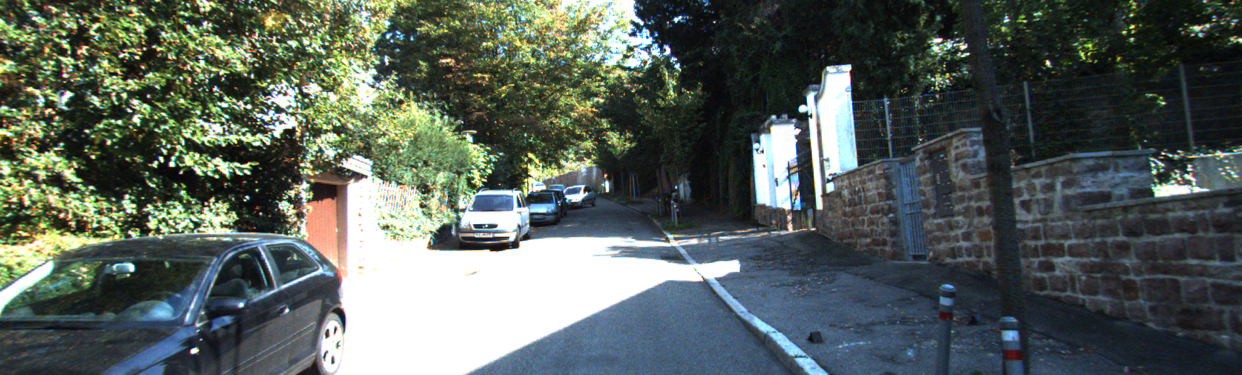

In [17]:
import torch
from pathlib import Path
from PIL import Image

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Enable one in Runtime > Change runtime type.")

# Count files in each split
for split in ["train", "val"]:
    img_dir = DATASET_DIR / "images" / split
    lbl_dir = DATASET_DIR / "labels" / split

    image_count = len(list(img_dir.glob("*.png")))
    label_count = len(list(lbl_dir.glob("*.txt")))

    print(f"\n{split.upper()}")
    print("Images:", image_count)
    print("Labels:", label_count)

# Test that an image can be opened
sample_path = next(
    (DATASET_DIR / "images" / "train").glob("*.png")
)

with Image.open(sample_path) as img:
    print("\nSample image:", sample_path.name)
    print("Image dimensions:", img.size)
    display(img)

In [18]:
from ultralytics import YOLO
import torch

# Load pretrained YOLO26 nano weights
model = YOLO("yolo26n.pt")

# Fine-tune on your KITTI dataset
results = model.train(
    data=str(DATA_YAML),
    epochs=10,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    patience=3,
    project="/content/runs",
    name="kitti_road_detection",
    exist_ok=True,
    seed=42
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/kitti_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=kitti_road_detection, nbs=64, nms=None, opset=None, optimize=

In [19]:
from pathlib import Path
from google.colab import files

MODEL_PATH = Path(
    "/content/runs/kitti_road_detection/weights/best.pt"
)

if MODEL_PATH.exists():
    print(f"Model found: {MODEL_PATH}")
    print(f"Size: {MODEL_PATH.stat().st_size / (1024 * 1024):.2f} MB")
    files.download(str(MODEL_PATH))
else:
    print("Model not found. Check the training output path.")

Model found: /content/runs/kitti_road_detection/weights/best.pt
Size: 5.16 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>